<a href="https://colab.research.google.com/github/DaniNguyen2509/Neiro-Quant/blob/main/notebooks/Neiro_Quant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🪙 NEIRO-QUANT: BẢNG ĐIỀU KHIỂN TÁC CHIẾN ĐỊNH LƯỢNG (ALL-IN-ONE)
> **100% CME Gold Futures (GCZ26) | Tự động tính toán GEX, Volume, Open Interest & Điểm vào lệnh**
> *Chạy 1 mạch duy nhất (Ctrl + F9 hoặc bấm Run cell bên dưới) là hiển thị toàn bộ kết quả.*

⚠️ [CHUA THAY FILE CSV] Hay bam nut 'Choose Files' ben duoi de tai file:
👉 Chon file 'options_prices_GCZ26.csv' tu may tinh cua anh.


Saving options_prices_GCZ26_near_the_money.csv to options_prices_GCZ26_near_the_money.csv
✅ [THANH CONG] DA NAP FILE THAT: 'Uploaded truc tiep (options_prices_GCZ26_near_the_money.csv)' (20 strikes ban dau)
🎯 [CHE DO NEAR THE MONEY] Da loc dung 15 strikes: $4000 -> $4350
[NEIRO-QUANT] Tính toán xong trong 186.70s! Spot CME: 4181.13 | Call Wall: 4300 (441 OI) | Put Wall: 4100 (394 OI)
📐 [ĐỘ LỆCH CHUẨN & BIÊN ĐỘ 1-SIGMA]:
   • ATM Straddle (Call + Put ATM): $84.10 | Implied Volatility (IV): 7.8%
   • Expected Move 1-Sigma (Brenner-Subrahmanyam): ±$105.40 (Biên độ cả kỳ)
   • Intraday Expected Move (Rule of 16): ±$20.42 (Vùng dao động trong ngày: $4160.71 - $4201.55)
⚡ PHẦN 1: BẢNG TÁC CHIẾN LƯỚT SÓNG TRONG NGÀY (INTRADAY SCALPING - ĂN 20-25 GIÁ VÀNG):


,Chien Luoc,Vung Gia Kich Hoat,Entry,Hard SL,Take Profit (TP),Ghi Chu
0,1. BUY MUA DUOI (Squeeze 4200),Vuot > 4202.50,4203.00,4198.50 ($4.5),4224.00 (An non 1$),MM vo tran Short -> Gamma Squeeze day gia len ...
1,2. SELL CAN TIEN TUYEN (Fade 4200),4198.50 - 4200.00,4199.00,4204.00 ($5.0),4181.13 (Hoi ve Spot),Can Vol cuc dai -> MM ban Futures chan dau kìm...
2,3. BUY BAT SAN ATM (Rebound 4175),4175.00 - 4176.50,4176.00,4171.00 ($5.0),4199.00,Dem Put ho tro hoi phuc ky thuat trong phien
3,4. SELL THUNG SAN ATM (Breakdown 4175),Thung < 4172.50,4172.00,4176.50 ($4.5),4151.00,Mat moc ATM Pivot -> Roi ve nac tiep theo 4150


-------------------------------------------------------------------------------------------------------------------
🏰 PHẦN 2: BẢNG TÁC CHIẾN PHỤC KÍCH THÀNH TRÌ (STRUCTURAL SWING WALLS - ĐÁNH SÓNG LỚN):


,Chien Luoc,Vung Gia Kich Hoat,Entry,Hard SL,Take Profit (TP),Ghi Chu
0,5. BAN DINH CALL WALL (4300),4298.50 - 4300.00,4299.00,4304.00 ($4.0),4200.00 / 4181.13,Call Wall 441 OI (Noc nha cuoi cung cua MM)
1,6. MUA DAY PUT WALL (4100),4100.00 - 4101.50,4100.50,4096.00 ($4.0),4181.13 / 4200.00,Major Put Wall 394 OI (Day be tong cuoi cung c...


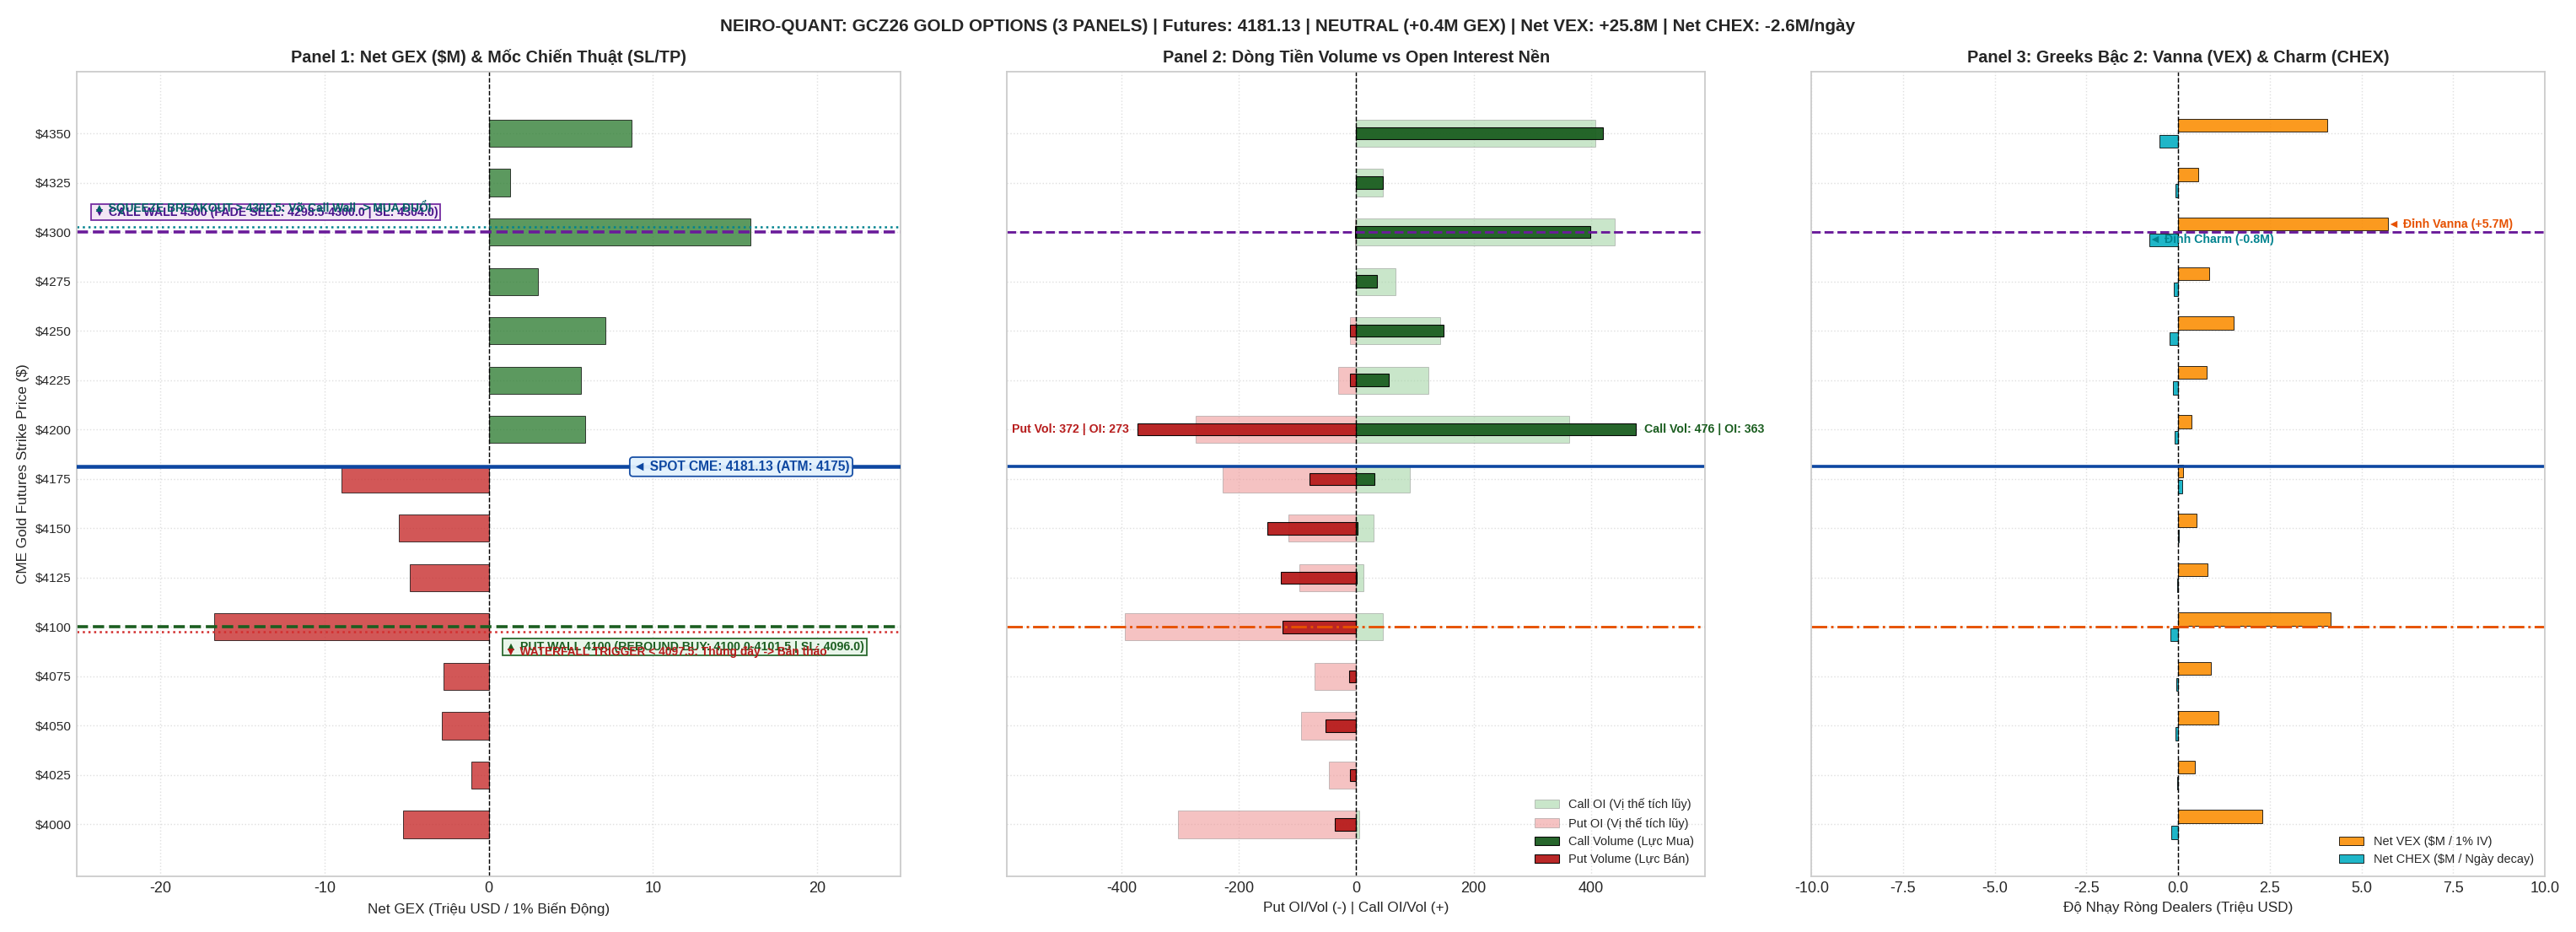

In [1]:
# @title
# ==============================================================================
# NEIRO-QUANT: BANG DIEU KHIEN TAC CHIEN DINH LUONG ALL-IN-ONE (100% CME GOLD GCZ26)
# ==============================================================================
# TU DONG 100%: Nap file CSV that -> Loc Near The Money -> Tinh GEX / VEX / CHEX -> Ve 3 Panels
# ==============================================================================

NEAR_THE_MONEY_ONLY = True
MAX_NEAR_STRIKES = 14  # 14 strikes (~+/- 7 quanh ATM) - Chuan Intraday Gold

PASTE_CLIPBOARD_HERE = """

"""

import os
import sys
if hasattr(sys.stdout, 'reconfigure'):
    try: sys.stdout.reconfigure(encoding='utf-8')
    except Exception: pass
import re
import io
import glob
import time
import math
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

t0 = time.time()

# 1. HAM CHUAN HOA SO LIEU & PARSER THONG MINH
def clean_val(v, default=0.0):
    if v is None: return default
    if isinstance(v, (int, float)): return default if (math.isnan(v) or math.isinf(v)) else float(v)
    s = str(v).strip()
    if not s or any(err in s.upper() for err in ('#ERROR', '#REF', '#VALUE', '#N/A', 'UNCH', 'NAN', 'NULL', 'NONE')) or s in ('-', '--', '.', 'N/A'): return default
    s = s.replace('"', '').replace("'", "").replace('$', '')
    while s.startswith(('=', '+')): s = s[1:].strip()
    if s.endswith(('s', 'S')) and len(s) > 1 and (s[-2].isdigit() or s[-2] == '.'): s = s[:-1].strip()
    if s.endswith('%'): s = s[:-1].strip()
    s = s.replace(',', '').replace(' ', '')
    try: return float(s)
    except Exception:
        m = re.search(r'[-+]?\d*\.?\d+', s)
        return float(m.group(0)) if m else default

def clean_strike(v):
    if v is None: return 0.0
    if isinstance(v, (int, float)): return float(v)
    s = str(v).strip().replace('"', '').replace("'", "")
    while s.startswith(('=', '+')): s = s[1:].strip()
    if s.endswith(('c', 'C', 'p', 'P')): s = s[:-1].strip()
    s = s.replace(',', '').replace(' ', '')
    try: return float(s)
    except Exception:
        m = re.search(r'\d[\d,]*\.?\d*', str(v))
        return float(m.group(0).replace(',', '')) if m else 0.0

def parse_df_from_raw(raw):
    cols_clean = [re.sub(r'[\s_\-]+', '', str(c).lower()) for c in raw.columns]
    col_map = {cols_clean[i]: raw.columns[i] for i in range(len(raw.columns))}
    stk_col = col_map.get('strike') or col_map.get('strikeprice') or raw.columns[0]
    rows = []
    if any(k in col_map for k in ['callbid', 'callvolume', 'callopeninterest', 'calllatest', 'callmid']):
        for _, r in raw.iterrows():
            stk = clean_strike(r.get(stk_col))
            if stk <= 0: continue
            rows.append({
                'strike': stk,
                'callBid': clean_val(r.get(col_map.get('callbid', ''))),
                'callAsk': clean_val(r.get(col_map.get('callask', ''))),
                'callMid': clean_val(r.get(col_map.get('callmid', ''))),
                'callLatest': clean_val(r.get(col_map.get('calllatest', ''))),
                'callVolume': clean_val(r.get(col_map.get('callvolume', col_map.get('callvol', '')))),
                'callOpenInterest': clean_val(r.get(col_map.get('callopeninterest', col_map.get('calloi', '')))),
                'callGamma': clean_val(r.get(col_map.get('callgamma', '0.0037')), default=0.0037) or 0.0037,
                'callIV': clean_val(r.get(col_map.get('calliv', '0.215')), default=0.215),
                'putBid': clean_val(r.get(col_map.get('putbid', ''))),
                'putAsk': clean_val(r.get(col_map.get('putask', ''))),
                'putMid': clean_val(r.get(col_map.get('putmid', ''))),
                'putLatest': clean_val(r.get(col_map.get('putlatest', ''))),
                'putVolume': clean_val(r.get(col_map.get('putvolume', col_map.get('putvol', '')))),
                'putOpenInterest': clean_val(r.get(col_map.get('putopeninterest', col_map.get('putoi', '')))),
                'putGamma': clean_val(r.get(col_map.get('putgamma', '0.0037')), default=0.0037) or 0.0037,
                'putIV': clean_val(r.get(col_map.get('putiv', '0.215')), default=0.215),
            })
    return pd.DataFrame(rows).sort_values('strike').reset_index(drop=True) if rows else pd.DataFrame()

# 2. NAP DU LIEU DA TANG
df_loaded = pd.DataFrame()
source_name = ""

if PASTE_CLIPBOARD_HERE.strip():
    try:
        raw_clip = pd.read_csv(io.StringIO(PASTE_CLIPBOARD_HERE.strip()), sep='\t' if '\t' in PASTE_CLIPBOARD_HERE else ',', on_bad_lines='skip')
        df_loaded = parse_df_from_raw(raw_clip)
        if not df_loaded.empty:
            source_name = "Clipboard (Dan tay truc tiep)"
    except Exception as e:
        print(f"[CANH BAO] Loi doc clipboard: {e}")

if df_loaded.empty:
    search_dirs = ['/content', '/content/drive/MyDrive/Neiro-Quant/data', 'data', '.', '../data']
    if not os.path.exists('/content/drive/MyDrive') and os.path.exists('/content'):
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
        except Exception:
            pass

    found_files = []
    for d in search_dirs:
        if os.path.exists(d):
            found_files.extend(glob.glob(os.path.join(d, '*.csv')))

    prioritized_files = sorted(
        list(set(found_files)),
        key=lambda f: (
            0 if 'options_prices_gcz' in f.lower() else
            1 if 'options_prices' in f.lower() else
            2 if 'options' in f.lower() else
            3 if 'gcz' in f.lower() else 4
        )
    )

    for fpath in prioritized_files:
        try:
            raw = pd.read_csv(fpath, encoding='utf-8-sig', encoding_errors='ignore', on_bad_lines='skip')
            df_temp = parse_df_from_raw(raw)
            if not df_temp.empty and len(df_temp) >= 5:
                df_loaded = df_temp
                source_name = fpath
                break
        except Exception:
            continue

if df_loaded.empty:
    github_raw_url = 'https://raw.githubusercontent.com/DaniNguyen2509/Neiro-Quant/main/data/options_prices_GCZ26.csv'
    try:
        raw_cloud = pd.read_csv(github_raw_url, on_bad_lines='skip')
        df_temp = parse_df_from_raw(raw_cloud)
        if not df_temp.empty and len(df_temp) >= 5:
            df_loaded = df_temp
            source_name = 'GitHub Cloud Sync (Tu dong 100% Zero-Touch)'
            print(f'☁️ [ZERO-TOUCH] Da nap thanh cong du lieu moi nhat tu GitHub Cloud Bot!')
    except Exception as e:
        pass

if df_loaded.empty and os.path.exists('/content'):
    try:
        from google.colab import files
        print("=" * 80)
        print("⚠️ [CHUA THAY FILE CSV] Hay bam nut 'Choose Files' ben duoi de tai file:")
        print("👉 Chon file 'options_prices_GCZ26.csv' tu may tinh cua anh.")
        print("=" * 80)
        uploaded = files.upload()
        for fname in uploaded.keys():
            raw = pd.read_csv(fname, encoding='utf-8-sig', encoding_errors='ignore', on_bad_lines='skip')
            df_temp = parse_df_from_raw(raw)
            if not df_temp.empty:
                df_loaded = df_temp
                source_name = f"Uploaded truc tiep ({fname})"
                break
    except Exception as e:
        print(f"[CANH BAO] Khong the mo hop thoai upload: {e}")

if df_loaded.empty:
    print("[NGUON DU LIEU] CHUA TIM THAY FILE -> Dang dung Benchmark GCZ26 du phong.")
    BENCHMARK_DATA = [
        {'strike': 4135.0, 'callBid': 133.2, 'callAsk': 133.6, 'callMid': 133.4, 'callLatest': 133.4, 'callVolume': 0.0, 'callOpenInterest': 75.0, 'callGamma': 0.00336, 'callIV': 0.21764, 'putBid': 87.2, 'putAsk': 87.6, 'putMid': 87.4, 'putLatest': 87.4, 'putVolume': 1.0, 'putOpenInterest': 37.0, 'putGamma': 0.00336, 'putIV': 0.21764},
        {'strike': 4150.0, 'callBid': 125.1, 'callAsk': 125.5, 'callMid': 125.3, 'callLatest': 125.3, 'callVolume': 17.0, 'callOpenInterest': 461.0, 'callGamma': 0.00360, 'callIV': 0.21620, 'putBid': 94.1, 'putAsk': 94.5, 'putMid': 94.3, 'putLatest': 94.3, 'putVolume': 15.0, 'putOpenInterest': 1162.0, 'putGamma': 0.00360, 'putIV': 0.21620},
        {'strike': 4175.0, 'callBid': 111.9, 'callAsk': 112.3, 'callMid': 112.1, 'callLatest': 112.1, 'callVolume': 26.0, 'callOpenInterest': 1039.0, 'callGamma': 0.00380, 'callIV': 0.21530, 'putBid': 105.9, 'putAsk': 106.3, 'putMid': 106.1, 'putLatest': 106.1, 'putVolume': 20.0, 'putOpenInterest': 437.0, 'putGamma': 0.00380, 'putIV': 0.21530},
        {'strike': 4200.0, 'callBid': 99.0, 'callAsk': 99.4, 'callMid': 99.2, 'callLatest': 99.2, 'callVolume': 646.0, 'callOpenInterest': 2444.0, 'callGamma': 0.00370, 'callIV': 0.21460, 'putBid': 118.0, 'putAsk': 118.4, 'putMid': 118.2, 'putLatest': 118.2, 'putVolume': 148.0, 'putOpenInterest': 2527.0, 'putGamma': 0.00370, 'putIV': 0.21460},
        {'strike': 4225.0, 'callBid': 86.4, 'callAsk': 86.8, 'callMid': 86.6, 'callLatest': 86.6, 'callVolume': 4.0, 'callOpenInterest': 338.0, 'callGamma': 0.00350, 'callIV': 0.21400, 'putBid': 130.4, 'putAsk': 130.8, 'putMid': 130.6, 'putLatest': 130.6, 'putVolume': 7.0, 'putOpenInterest': 264.0, 'putGamma': 0.00350, 'putIV': 0.21400}
    ]
    df_loaded = pd.DataFrame(BENCHMARK_DATA)
    source_name = "Benchmark CME GCZ26 Mau"
else:
    print(f"✅ [THANH CONG] DA NAP FILE THAT: '{source_name}' ({len(df_loaded)} strikes ban dau)")

# 3. TINH TOAN MA TRAN QUANT & CAC MOC TAC CHIEN
atm_idx = (df_loaded['callMid'] - df_loaded['putMid']).abs().idxmin()
atm_strike = float(df_loaded.loc[atm_idx, 'strike'])
c_mid_atm = float(df_loaded.loc[atm_idx, 'callMid'])
p_mid_atm = float(df_loaded.loc[atm_idx, 'putMid'])
r, dte_days = 0.045, 38.0
T_years = max(dte_days / 365.0, 1.0 / 365.0)
spot_price = atm_strike + math.exp(r * T_years) * (c_mid_atm - p_mid_atm)

MULT = 100.0
scale = (spot_price ** 2) * 0.01 / 1e6
df_loaded['callGEX'] = df_loaded['callGamma'] * df_loaded['callOpenInterest'] * MULT * scale
df_loaded['putGEX']  = - (df_loaded['putGamma'] * df_loaded['putOpenInterest'] * MULT * scale)
df_loaded['netGEX']  = df_loaded['callGEX'] + df_loaded['putGEX']
df_loaded['callDeltaFlow'] = df_loaded['callVolume'] * MULT * scale
df_loaded['putDeltaFlow']  = - (df_loaded['putVolume'] * MULT * scale)
df_loaded['netDeltaFlow']  = df_loaded['callDeltaFlow'] + df_loaded['putDeltaFlow']

# Greeks Bac 2: Vanna (VEX) & Charm (CHEX) (Black-76)
atm_straddle = max(1.0, c_mid_atm + p_mid_atm)
sigma_atm = float(np.clip(atm_straddle / (0.7979 * spot_price * np.sqrt(T_years)), 0.01, 2.0))
expected_move_1s = atm_straddle / 0.7979
rule16_daily_move = (sigma_atm / 16.0) * spot_price

strikes_all = df_loaded['strike'].values.astype(float)
denom = sigma_atm * np.sqrt(T_years)
d1 = (np.log(np.maximum(1e-4, spot_price / strikes_all)) + 0.5 * (sigma_atm ** 2) * T_years) / denom
d2 = d1 - denom
pdf_d1 = (1.0 / np.sqrt(2.0 * np.pi)) * np.exp(-0.5 * (d1 ** 2))
cdf_d1 = 0.5 * (1.0 + np.vectorize(math.erf)(d1 / np.sqrt(2.0)))
df_disc = np.exp(-r * T_years)

vanna = - df_disc * pdf_d1 * (d2 / sigma_atm)
charm_call = - df_disc * (pdf_d1 * (r / denom - d2 / (2.0 * T_years)) - r * cdf_d1)
charm_put = charm_call - r * df_disc

df_loaded['callVEX'] = vanna * df_loaded['callOpenInterest'] * MULT * spot_price * 0.01 / 1e6
df_loaded['putVEX'] = - (vanna * df_loaded['putOpenInterest'] * MULT * spot_price * 0.01 / 1e6)
df_loaded['netVEX'] = df_loaded['callVEX'] + df_loaded['putVEX']

df_loaded['callCHEX'] = (charm_call / 365.0) * df_loaded['callOpenInterest'] * MULT * spot_price / 1e6
df_loaded['putCHEX'] = - ((charm_put / 365.0) * df_loaded['putOpenInterest'] * MULT * spot_price / 1e6)
df_loaded['netCHEX'] = df_loaded['callCHEX'] + df_loaded['putCHEX']

# Structural Walls from full dataset
call_wall_row = df_loaded.loc[df_loaded['callOpenInterest'].idxmax()]
put_wall_row  = df_loaded.loc[df_loaded['putOpenInterest'].idxmax()]
call_wall = float(call_wall_row['strike'])
call_wall_oi = int(call_wall_row['callOpenInterest'])
put_wall = float(put_wall_row['strike'])
put_wall_oi = int(put_wall_row['putOpenInterest'])
total_net_gex = float(df_loaded['netGEX'].sum())
total_net_vex = float(df_loaded['netVEX'].sum())
total_net_chex = float(df_loaded['netCHEX'].sum())
regime = 'LONG_GAMMA' if total_net_gex > 10.0 else ('SHORT_GAMMA' if total_net_gex < -10.0 else 'NEUTRAL')
squeeze_trigger = call_wall + 2.50
waterfall_trigger = put_wall - 2.50

# Loc Near The Money cho visual khong bi de chu
if NEAR_THE_MONEY_ONLY and len(df_loaded) > MAX_NEAR_STRIKES:
    half = MAX_NEAR_STRIKES // 2
    start = max(0, atm_idx - half)
    end = min(len(df_loaded), atm_idx + half + 1)
    df = df_loaded.iloc[start:end].copy().reset_index(drop=True)
    print(f"🎯 [CHE DO NEAR THE MONEY] Da loc dung {len(df)} strikes: ${df['strike'].min():.0f} -> ${df['strike'].max():.0f}")
else:
    df = df_loaded.copy()

strikes = df['strike'].values
step = float(np.diff(strikes).min()) if len(strikes) > 1 else 25.0

strikes_above = strikes[strikes > spot_price]
strike_above = float(strikes_above[0]) if len(strikes_above) > 0 else call_wall
next_above = float(strikes_above[1]) if len(strikes_above) > 1 else strike_above + step

strikes_below = strikes[strikes <= spot_price]
strike_below = float(strikes_below[-1]) if len(strikes_below) > 0 else put_wall
next_below = float(strikes_below[-2]) if len(strikes_below) > 1 else strike_below - step

buffer_up = min(step * 0.10, 2.50)
buffer_down = min(step * 0.10, 2.50)
front_run_tp = 1.00

df_intraday = pd.DataFrame([
    {'Chien Luoc': f'1. BUY MUA DUOI (Squeeze {strike_above:.0f})', 'Vung Gia Kich Hoat': f'Vuot > {strike_above + buffer_up:.2f}', 'Entry': f'{strike_above + buffer_up + 0.50:.2f}', 'Hard SL': f'{strike_above - 1.50:.2f} ($4.5)', 'Take Profit (TP)': f'{next_above - front_run_tp:.2f} (An non 1$)', 'Ghi Chu': f'MM vo tran Short -> Gamma Squeeze day gia len nac {next_above:.0f}'},
    {'Chien Luoc': f'2. SELL CAN TIEN TUYEN (Fade {strike_above:.0f})', 'Vung Gia Kich Hoat': f'{strike_above - 1.50:.2f} - {strike_above:.2f}', 'Entry': f'{strike_above - 1.00:.2f}', 'Hard SL': f'{strike_above + buffer_up + 1.50:.2f} ($5.0)', 'Take Profit (TP)': f'{spot_price:.2f} (Hoi ve Spot)', 'Ghi Chu': f'Can Vol cuc dai -> MM ban Futures chan dau kìm gia'},
    {'Chien Luoc': f'3. BUY BAT SAN ATM (Rebound {strike_below:.0f})', 'Vung Gia Kich Hoat': f'{strike_below:.2f} - {strike_below + 1.50:.2f}', 'Entry': f'{strike_below + 1.00:.2f}', 'Hard SL': f'{strike_below - 4.00:.2f} ($5.0)', 'Take Profit (TP)': f'{strike_above - front_run_tp:.2f}', 'Ghi Chu': f'Dem Put ho tro hoi phuc ky thuat trong phien'},
    {'Chien Luoc': f'4. SELL THUNG SAN ATM (Breakdown {strike_below:.0f})', 'Vung Gia Kich Hoat': f'Thung < {strike_below - buffer_down:.2f}', 'Entry': f'{strike_below - buffer_down - 0.50:.2f}', 'Hard SL': f'{strike_below + 1.50:.2f} ($4.5)', 'Take Profit (TP)': f'{next_below + front_run_tp:.2f}', 'Ghi Chu': f'Mat moc ATM Pivot -> Roi ve nac tiep theo {next_below:.0f}'}
])

df_swing = pd.DataFrame([
    {'Chien Luoc': f'5. BAN DINH CALL WALL ({call_wall:.0f})', 'Vung Gia Kich Hoat': f'{call_wall - 1.50:.2f} - {call_wall:.2f}', 'Entry': f'{call_wall - 1.00:.2f}', 'Hard SL': f'{call_wall + 4.00:.2f} ($4.0)', 'Take Profit (TP)': f'{strike_above:.2f} / {spot_price:.2f}', 'Ghi Chu': f'Call Wall {call_wall_oi:,} OI (Noc nha cuoi cung cua MM)'},
    {'Chien Luoc': f'6. MUA DAY PUT WALL ({put_wall:.0f})', 'Vung Gia Kich Hoat': f'{put_wall:.2f} - {put_wall + 1.50:.2f}', 'Entry': f'{put_wall + 0.50:.2f}', 'Hard SL': f'{put_wall - 4.00:.2f} ($4.0)', 'Take Profit (TP)': f'{spot_price:.2f} / {strike_above:.2f}', 'Ghi Chu': f'Major Put Wall {put_wall_oi:,} OI (Day be tong cuoi cung cua MM)'}
])

# 4. VE BIEU DO 3 PANELS PRO QUANT
net_gex = df['netGEX'].values
net_vex = df['netVEX'].values
net_chex = df['netCHEX'].values
call_oi = df['callOpenInterest'].values
put_oi = df['putOpenInterest'].values
call_vol = df['callVolume'].values
put_vol = df['putVolume'].values

bar_h = step * 0.55
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(23.5, 8.5), dpi=130, sharey=True, gridspec_kw={'width_ratios': [1.18, 1.0, 1.05]})
y_bottom = strikes.min() - step * 1.05
y_top = strikes.max() + step * 1.25
ax1.set_ylim(y_bottom, y_top)

# PANEL 1: NET GEX
colors = ['#2E7D32' if x >= 0 else '#C62828' for x in net_gex]
ax1.barh(strikes, net_gex, height=bar_h, color=colors, alpha=0.78, edgecolor='black', linewidth=0.5)
ax1.axvline(0, color='black', linewidth=0.8, linestyle='--')

max_abs_gex = max(abs(net_gex.min()), abs(net_gex.max())) if len(net_gex) > 0 else 50.0
gex_span = max(max_abs_gex * 1.5, 25.0)
ax1.set_xlim(-gex_span, gex_span)

ax1.axhline(spot_price, color='#0D47A1', linewidth=2.5, linestyle='-', zorder=4)
ax1.text(gex_span * 0.35, spot_price, f'◄ SPOT CME: {spot_price:.2f} (ATM: {atm_strike:.0f})',
         color='#0D47A1', fontsize=8.6, fontweight='bold', va='center',
         bbox=dict(boxstyle='round,pad=0.25', facecolor='#E3F2FD', edgecolor='#0D47A1', alpha=0.95), zorder=5)

if strikes.min() <= call_wall <= strikes.max():
    ax1.axhline(call_wall, color='#6A1B9A', linewidth=2.0, linestyle='--')
    ax1.text(-gex_span * 0.96, call_wall + step * 0.40,
             f"▼ CALL WALL {call_wall:.0f} (FADE SELL: {call_wall-1.5:.1f}-{call_wall:.1f} | SL: {call_wall+4:.1f})",
             color='#4A148C', fontsize=7.8, fontweight='bold', va='center', ha='left',
             bbox=dict(boxstyle='square,pad=0.2', facecolor='#F3E5F5', edgecolor='#6A1B9A', alpha=0.92))
    ax1.axhline(squeeze_trigger, color='#00838F', linewidth=1.4, linestyle=':')
    ax1.text(-gex_span * 0.96, squeeze_trigger + step * 0.40,
             f"▲ SQUEEZE BREAKOUT > {squeeze_trigger:.1f}: Vỡ Call Wall -> MUA ĐUỔI",
             color='#006064', fontsize=7.6, fontweight='bold', va='center', ha='left')

if strikes.min() <= put_wall <= strikes.max():
    ax1.axhline(put_wall, color='#1B5E20', linewidth=2.0, linestyle='--')
    ax1.text(gex_span * 0.04, put_wall - step * 0.40,
             f"▲ PUT WALL {put_wall:.0f} (REBOUND BUY: {put_wall:.1f}-{put_wall+1.5:.1f} | SL: {put_wall-4:.1f})",
             color='#1B5E20', fontsize=7.8, fontweight='bold', va='center', ha='left',
             bbox=dict(boxstyle='square,pad=0.2', facecolor='#E8F5E9', edgecolor='#1B5E20', alpha=0.92))
    ax1.axhline(waterfall_trigger, color='#D32F2F', linewidth=1.4, linestyle=':')
    ax1.text(gex_span * 0.04, waterfall_trigger - step * 0.40,
             f"▼ WATERFALL TRIGGER < {waterfall_trigger:.1f}: Thủng đáy -> Bán tháo",
             color='#B71C1C', fontsize=7.6, fontweight='bold', va='center', ha='left')

ax1.set_title('Panel 1: Net GEX ($M) & Mốc Chiến Thuật (SL/TP)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Net GEX (Triệu USD / 1% Biến Động)', fontsize=9.5)
ax1.set_ylabel('CME Gold Futures Strike Price ($)', fontsize=9.5)
ax1.set_yticks(strikes)
ax1.set_yticklabels([f'${s:.0f}' for s in strikes], fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# PANEL 2: VOLUME vs OPEN INTEREST
ax2.barh(strikes, call_oi, height=bar_h, color='#A5D6A7', alpha=0.6, label='Call OI (Vị thế tích lũy)', edgecolor='gray', linewidth=0.4)
ax2.barh(strikes, -put_oi, height=bar_h, color='#EF9A9A', alpha=0.6, label='Put OI (Vị thế tích lũy)', edgecolor='gray', linewidth=0.4)
ax2.barh(strikes, call_vol, height=bar_h * 0.45, color='#1B5E20', alpha=0.95, label='Call Volume (Lực Mua)', edgecolor='black', linewidth=0.6)
ax2.barh(strikes, -put_vol, height=bar_h * 0.45, color='#B71C1C', alpha=0.95, label='Put Volume (Lực Bán)', edgecolor='black', linewidth=0.6)
ax2.axvline(0, color='black', linewidth=0.8, linestyle='--')

if len(df) > 0 and call_vol.max() > 0:
    top_c_idx = df['callVolume'].idxmax()
    ax2.text(df.loc[top_c_idx, 'callVolume'] + 15, df.loc[top_c_idx, 'strike'], f"Call Vol: {int(df.loc[top_c_idx, 'callVolume'])} | OI: {int(df.loc[top_c_idx, 'callOpenInterest'])}", color='#1B5E20', fontsize=7.8, fontweight='bold', va='center')
if len(df) > 0 and put_vol.max() > 0:
    top_p_idx = df['putVolume'].idxmax()
    ax2.text(-df.loc[top_p_idx, 'putVolume'] - 15, df.loc[top_p_idx, 'strike'], f"Put Vol: {int(df.loc[top_p_idx, 'putVolume'])} | OI: {int(df.loc[top_p_idx, 'putOpenInterest'])}", color='#B71C1C', fontsize=7.8, fontweight='bold', va='center', ha='right')

ax2.axhline(spot_price, color='#0D47A1', linewidth=2.0, linestyle='-')
if strikes.min() <= call_wall <= strikes.max():
    ax2.axhline(call_wall, color='#6A1B9A', linewidth=1.6, linestyle='--')
if strikes.min() <= put_wall <= strikes.max():
    ax2.axhline(put_wall, color='#E65100', linewidth=1.6, linestyle='-.')

max_vol_oi = max(call_oi.max() if len(call_oi) else 0, put_oi.max() if len(put_oi) else 0, call_vol.max() if len(call_vol) else 0, put_vol.max() if len(put_vol) else 0)
p2_span = max(max_vol_oi * 1.25, 200.0)
ax2.set_xlim(-p2_span, p2_span)
ax2.set_title('Panel 2: Dòng Tiền Volume vs Open Interest Nền', fontsize=11, fontweight='bold')
ax2.set_xlabel('Put OI/Vol (-) | Call OI/Vol (+)', fontsize=9.5)
ax2.legend(loc='lower right', fontsize=8.0, framealpha=0.95)
ax2.grid(True, linestyle=':', alpha=0.6)

# PANEL 3: VANNA & CHARM
ax3.barh(strikes + step * 0.16, net_vex, height=bar_h * 0.48, color='#FB8C00', alpha=0.88, label='Net VEX ($M / 1% IV)', edgecolor='black', linewidth=0.5)
ax3.barh(strikes - step * 0.16, net_chex, height=bar_h * 0.48, color='#00ACC1', alpha=0.88, label='Net CHEX ($M / Ngày decay)', edgecolor='black', linewidth=0.5)
ax3.axvline(0, color='black', linewidth=0.8, linestyle='--')

ax3.axhline(spot_price, color='#0D47A1', linewidth=2.0, linestyle='-')
if strikes.min() <= call_wall <= strikes.max():
    ax3.axhline(call_wall, color='#6A1B9A', linewidth=1.6, linestyle='--')
if strikes.min() <= put_wall <= strikes.max():
    ax3.axhline(put_wall, color='#E65100', linewidth=1.6, linestyle='-.')

if len(df) > 0:
    top_vex_idx = (df['netVEX'].abs()).idxmax()
    ax3.text(df.loc[top_vex_idx, 'netVEX'], df.loc[top_vex_idx, 'strike'] + step * 0.16, f"◄ Đỉnh Vanna ({df.loc[top_vex_idx, 'netVEX']:+.1f}M)", color='#E65100', fontsize=7.8, fontweight='bold', va='center')
    top_chex_idx = (df['netCHEX'].abs()).idxmax()
    ax3.text(df.loc[top_chex_idx, 'netCHEX'], df.loc[top_chex_idx, 'strike'] - step * 0.16, f"◄ Đỉnh Charm ({df.loc[top_chex_idx, 'netCHEX']:+.1f}M)", color='#00838F', fontsize=7.8, fontweight='bold', va='center')

max_vc = max(abs(net_vex.min()) if len(net_vex) else 0, abs(net_vex.max()) if len(net_vex) else 0, abs(net_chex.min()) if len(net_chex) else 0, abs(net_chex.max()) if len(net_chex) else 0)
p3_span = max(max_vc * 1.35, 10.0)
ax3.set_xlim(-p3_span, p3_span)
ax3.set_title('Panel 3: Greeks Bậc 2: Vanna (VEX) & Charm (CHEX)', fontsize=11, fontweight='bold')
ax3.set_xlabel('Độ Nhạy Ròng Dealers (Triệu USD)', fontsize=9.5)
ax3.legend(loc='lower right', fontsize=8.0, framealpha=0.95)
ax3.grid(True, linestyle=':', alpha=0.6)

header_title = f'NEIRO-QUANT: GCZ26 GOLD OPTIONS (3 PANELS) | Futures: {spot_price:.2f} | {regime} ({total_net_gex:+.1f}M GEX) | Net VEX: {total_net_vex:+.1f}M | Net CHEX: {total_net_chex:+.1f}M/ngày'
fig.suptitle(header_title, fontsize=11.5, fontweight='bold')

plt.tight_layout()
chart_file = 'quant_truevision_map.png'
plt.savefig(chart_file, dpi=130)
plt.close()

t1 = time.time()
print(f'[NEIRO-QUANT] Tính toán xong trong {t1 - t0:.2f}s! Spot CME: {spot_price:.2f} | Call Wall: {call_wall:.0f} ({call_wall_oi} OI) | Put Wall: {put_wall:.0f} ({put_wall_oi} OI)')
print('=' * 115)
print(f"📐 [ĐỘ LỆCH CHUẨN & BIÊN ĐỘ 1-SIGMA]:")
print(f"   • ATM Straddle (Call + Put ATM): ${atm_straddle:.2f} | Implied Volatility (IV): {sigma_atm*100:.1f}%")
print(f"   • Expected Move 1-Sigma (Brenner-Subrahmanyam): ±${expected_move_1s:.2f} (Biên độ cả kỳ)")
print(f"   • Intraday Expected Move (Rule of 16): ±${rule16_daily_move:.2f} (Vùng dao động trong ngày: ${spot_price - rule16_daily_move:.2f} - ${spot_price + rule16_daily_move:.2f})")
print('=' * 115)

try:
    from IPython.display import Image, display
    print('⚡ PHẦN 1: BẢNG TÁC CHIẾN LƯỚT SÓNG TRONG NGÀY (INTRADAY SCALPING - ĂN 20-25 GIÁ VÀNG):')
    display(df_intraday)
    print('-' * 115)
    print('🏰 PHẦN 2: BẢNG TÁC CHIẾN PHỤC KÍCH THÀNH TRÌ (STRUCTURAL SWING WALLS - ĐÁNH SÓNG LỚN):')
    display(df_swing)
    print('=' * 115)
    display(Image(chart_file, width=1200))
except Exception:
    print('PHẦN 1: INTRADAY SCALPING:')
    print(df_intraday.to_string(index=False))
    print('PHẦN 2: STRUCTURAL SWING WALLS:')
    print(df_swing.to_string(index=False))
